# Exploratory Data Analysis — Philosophical Minds Meetup

This notebook explores the two Meetup exports in `data/`:

| Section | File | Granularity |
|---|---|---|
| 1 | `group_members.csv` | one row per **member** (profile and lifetime engagement counters) |
| 2 | `group_attendance.csv` | one row per **member × event RSVP** |

Each section contains summary statistics, an EDA of every attribute and the key findings. Section 3 brings the findings together.

> **Privacy:** member names and profile URLs are personal data. They are only counted (nulls, uniques, duplicates) and then dropped. Members are referred to by `Member ID` only.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import re

import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("../data")
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [2]:
PII_COLS = {"Name", "Member Name", "URL of Member Profile"}


def overview(df: pd.DataFrame) -> pd.DataFrame:
    """Shape, duplicates and a per-column quality table."""
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns | fully duplicated rows: {df.duplicated().sum()}")
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
        "example": df.apply(lambda s: "<redacted>" if s.name in PII_COLS
                            else (s.dropna().iloc[0] if s.notna().any() else None)),
    })


def profile_numeric(s: pd.Series, log: bool = False, bins: int = 30) -> pd.Series:
    """Extended descriptive stats + histogram/boxplot for a numeric attribute."""
    stats = pd.Series({
        "count": s.count(), "sum": s.sum(), "mean": s.mean(), "median": s.median(),
        "std": s.std(), "min": s.min(), "q25": s.quantile(.25), "q75": s.quantile(.75),
        "q90": s.quantile(.9), "q99": s.quantile(.99), "max": s.max(),
        "skew": s.skew(), "kurtosis": s.kurt(),
        "zero_%": (s == 0).mean() * 100, "iqr_outliers": len(iqr_outliers(s)),
    }, name=s.name)
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
    sns.histplot(s, bins=bins, ax=axes[0], color="steelblue", discrete=s.nunique() < 40)
    if log:
        axes[0].set_yscale("log")
    axes[0].set_title(f"{s.name} — distribution" + (" (log y)" if log else ""))
    sns.boxplot(x=s, ax=axes[1], color="steelblue")
    axes[1].set_title(f"{s.name} — boxplot")
    plt.tight_layout(); plt.show()
    return stats


def profile_categorical(s: pd.Series, top: int = 15, plot: bool = True) -> pd.DataFrame:
    """Value counts with percentages and a horizontal bar chart."""
    vc = s.value_counts(dropna=False)
    out = pd.DataFrame({"count": vc, "%": (vc / vc.sum() * 100).round(1)})
    print(f"{s.name}: {s.nunique()} distinct values, {s.isna().sum()} null")
    if plot:
        head = out.head(top)
        ax = head["count"][::-1].plot(kind="barh", figsize=(10, 0.35 * len(head) + 1), color="darkorange")
        ax.set_title(f"{s.name} — top {len(head)} values"); ax.set_ylabel("")
        plt.show()
    return out.head(top)


def profile_date(s: pd.Series, freq: str = "ME", cumulative: bool = False) -> pd.Series:
    """Range, per-year counts and a per-period bar chart for a datetime attribute."""
    print(f"{s.name}: {s.min().date()} -> {s.max().date()} | null: {s.isna().sum()} | distinct: {s.nunique()}")
    per = s.dropna().dt.to_period(freq.rstrip("E")).value_counts().sort_index()
    per = per.reindex(pd.period_range(per.index.min(), per.index.max(), freq=per.index.freq), fill_value=0)
    fig, ax = plt.subplots(figsize=(14, 3.5))
    ax.bar(per.index.to_timestamp(), per.values, width=20, color="seagreen", label="per month")
    ax.set_title(f"{s.name} — count per month")
    if cumulative:
        ax2 = ax.twinx(); ax2.plot(per.index.to_timestamp(), per.cumsum().values, color="black", label="cumulative")
        ax2.set_ylabel("cumulative"); ax2.grid(False)
        fig.legend(loc="upper left", bbox_to_anchor=(0.06, 0.88))
    plt.show()
    return s.dt.year.value_counts().sort_index().rename("rows per year")


def iqr_outliers(s: pd.Series, k: float = 1.5) -> pd.Series:
    q1, q3 = s.quantile([0.25, 0.75])
    return s[(s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))]


def top_share(s: pd.Series, frac: float = 0.1) -> float:
    """Share of the column total held by the top `frac` of rows."""
    s = s.sort_values(ascending=False)
    return s.head(max(1, int(len(s) * frac))).sum() / s.sum()

---
## 1. `group_members.csv`

One row per group member: profile information (location, photo, intro, role), key dates (joined, last visit, last attended) and lifetime engagement counters (RSVPs, attendance, no-shows).

### 1.1 Summary statistics

In [3]:
members_raw = pd.read_csv(DATA_DIR / "group_members.csv")
overview(members_raw)

Shape: 1,620 rows x 16 columns | fully duplicated rows: 0


,dtype,non_null,null,null_%,n_unique,example
Name,str,1620,0,0.0,1472,<redacted>
Title,float64,0,1620,100.0,0,None
Member ID,int64,1620,0,0.0,1620,469249557
Location,str,1620,0,0.0,202,Langenthal
Joined Group on,str,1620,0,0.0,832,"March 18, 2025"
Last visited group on,str,1620,0,0.0,804,"March 18, 2025"
Last Attended,str,509,1111,68.6,79,"October 8, 2026"
All time RSVPs,int64,1620,0,0.0,35,0
All time 'Yes' RSVPs,int64,1620,0,0.0,29,0
All time 'No' RSVPs,int64,1620,0,0.0,14,0


In [4]:
DATE_COLS = ["Joined Group on", "Last visited group on", "Last Attended"]
YES_COL = "All time 'Yes' RSVPs"
COUNT_COLS = ["All time RSVPs", "All time 'Yes' RSVPs", "All time 'No' RSVPs", "Events attended", "No shows"]

members = members_raw.copy()
for c in DATE_COLS:
    members[c] = pd.to_datetime(members[c], format="%B %d, %Y")

# Personal / non-informative columns: profile before dropping
print(f"Name: {members['Name'].nunique()} distinct display names for {len(members)} members "
      f"({members['Name'].duplicated().sum()} duplicates, so names are not identifiers)")
print(f"URL of Member Profile: unique per row = {members['URL of Member Profile'].is_unique}; "
      f"always ends with Member ID = {(members['URL of Member Profile'].str.rstrip('/').str.split('/').str[-1] == members['Member ID'].astype(str)).all()}")
print(f"Title: {members['Title'].isna().mean():.0%} null")
members = members.drop(columns=["Name", "URL of Member Profile", "Title"])

members[COUNT_COLS].describe().T

Name: 1472 distinct display names for 1620 members (148 duplicates, so names are not identifiers)
URL of Member Profile: unique per row = True; always ends with Member ID = True
Title: 100% null


,count,mean,std,min,25%,50%,75%,max
All time RSVPs,1620.0,1.44e+00,4.21,0.0,0.0,0.0,1.0,76.0
All time 'Yes' RSVPs,1620.0,9.96e-01,3.43,0.0,0.0,0.0,1.0,73.0
All time 'No' RSVPs,1620.0,3.78e-01,1.15,0.0,0.0,0.0,0.0,13.0
Events attended,1620.0,9.30e-01,3.30,0.0,0.0,0.0,1.0,72.0
No shows,1620.0,3.09e-03,0.06,0.0,0.0,0.0,0.0,1.0


In [5]:
members.describe(include=["datetime"]).T

,count,mean,min,25%,50%,75%,max
Joined Group on,1620,2024-09-07 17:20:00,2022-01-16 00:00:00,2023-07-19 00:00:00,2025-01-03 12:00:00,2025-11-22 06:00:00,2026-10-25 00:00:00
Last visited group on,1620,2025-04-24 10:51:33.333333,2022-01-27 00:00:00,2024-06-30 18:00:00,2025-10-04 00:00:00,2026-04-30 06:00:00,2026-10-25 00:00:00
Last Attended,509,2024-10-01 00:25:27.701375,2022-02-10 00:00:00,2023-09-01 00:00:00,2024-10-23 00:00:00,2026-03-05 00:00:00,2026-10-08 00:00:00


### 1.2 EDA per attribute

#### `Member ID`

In [6]:
print(f"Unique: {members['Member ID'].is_unique} | range {members['Member ID'].min():,} - {members['Member ID'].max():,}")
# Meetup IDs grow over time: the ID shows when the Meetup *account* was created, not when the member joined the group
print(f"Spearman corr(Member ID, Joined Group on): "
      f"{members['Member ID'].corr(members['Joined Group on'].astype('int64'), method='spearman'):.2f}")

Unique: True | range 409,858 - 484,663,799
Spearman corr(Member ID, Joined Group on): 0.42


#### `Location`

Raw distinct locations: 202 -> normalised: 197
Members located in Zürich: 72.2%
Location_norm: 197 distinct values, 0 null


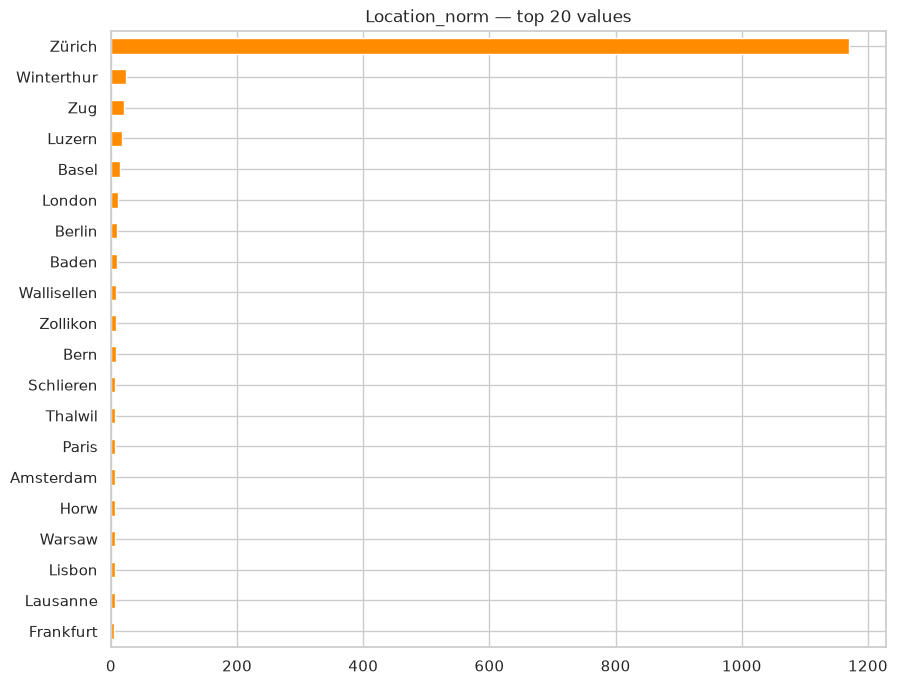

,count,%
Location_norm,,
Zürich,1170,72.2
Winterthur,24,1.5
Zug,21,1.3
Luzern,18,1.1
Basel,15,0.9
London,12,0.7
Berlin,10,0.6
Baden,9,0.6
Wallisellen,8,0.5


In [7]:
def normalise_location(x: str) -> str:
    x = x.split(",")[0].strip()
    return {"Zurich": "Zürich", "Zuerich": "Zürich", "Geneva": "Genève", "Lucerne": "Luzern"}.get(x, x)

members["Location_norm"] = members["Location"].map(normalise_location)
print(f"Raw distinct locations: {members['Location'].nunique()} -> normalised: {members['Location_norm'].nunique()}")
members["is_zurich"] = members["Location_norm"].eq("Zürich")
print(f"Members located in Zürich: {members['is_zurich'].mean():.1%}")
profile_categorical(members["Location_norm"], top=20)

#### `Joined Group on`

Joined Group on: 2022-01-16 -> 2026-10-25 | null: 0 | distinct: 832


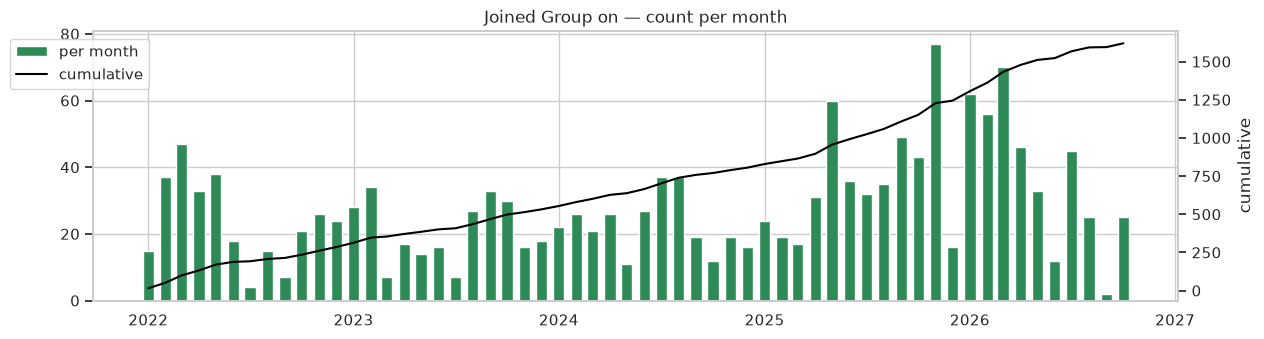

Joined Group on,2022,2023,2024,2025,2026
rows per year,285,247,273,439,376


Busiest join days:


,new members
date,
2026-10-19,18
2025-09-30,8
2025-05-04,8
2023-12-08,7
2026-03-25,7


Joins by weekday (%):
Joined Group on
Monday       14.9
Tuesday      13.6
Wednesday    18.3
Thursday     12.0
Friday       12.3
Saturday     12.4
Sunday       16.5


In [8]:
display(profile_date(members["Joined Group on"], cumulative=True).to_frame().T)
jg = members["Joined Group on"]
print("Busiest join days:")
display(jg.value_counts().head(5).rename_axis("date").to_frame("new members"))
print("Joins by weekday (%):")
print((jg.dt.day_name().value_counts(normalize=True).reindex(WEEKDAYS) * 100).round(1).to_string())

#### `Last visited group on`

Last visited group on: 2022-01-27 -> 2026-10-25 | null: 0 | distinct: 804


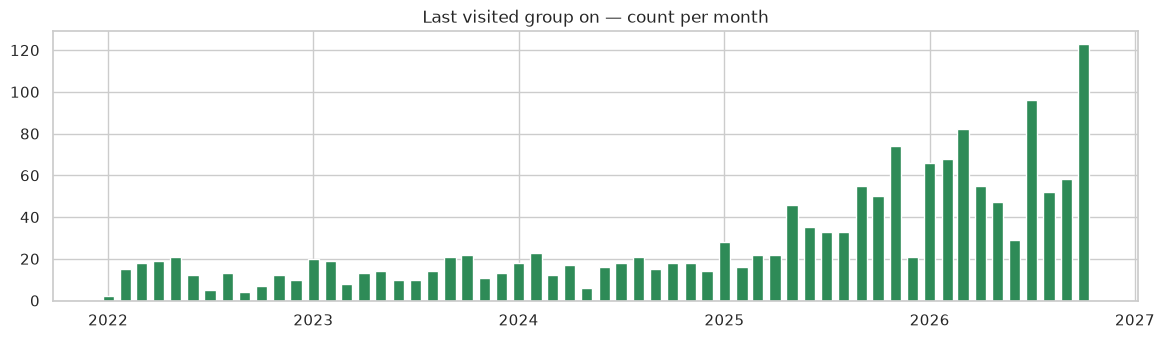

Last visited group on,2022,2023,2024,2025,2026
rows per year,138,175,196,435,676


Reference date (latest date in file): 2026-10-25
Last visit on the same day as joining (never came back to the page): 41.4%
Visited in the last 90 days: 16.0% | dormant >6 months: 74.6% | >1 year: 51.7%
Negative join->visit gaps (data error): 26


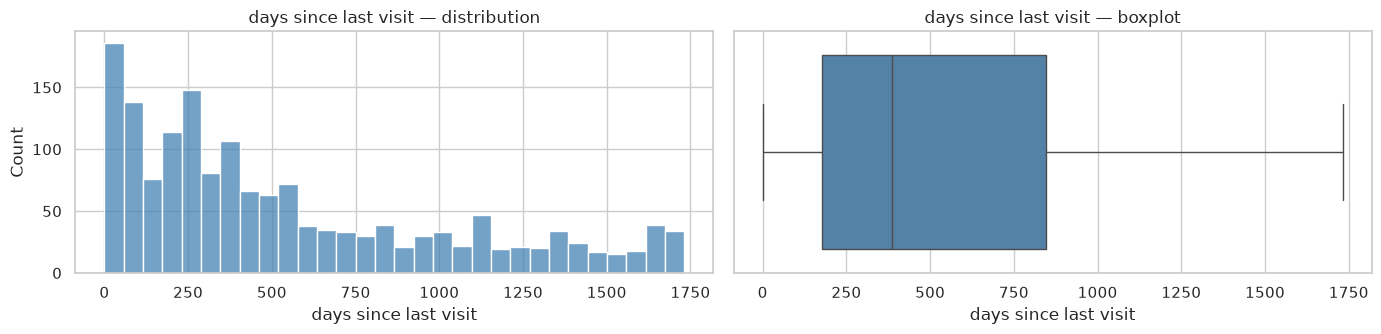

count             1620.00
sum             888647.00
mean               548.55
median             386.00
std                483.60
min                  0.00
q25                177.75
q75                846.25
q90               1356.50
q99               1699.05
max               1732.00
skew                 0.92
kurtosis            -0.29
zero_%               0.31
iqr_outliers         0.00
Name: days since last visit, dtype: float64

In [9]:
display(profile_date(members["Last visited group on"]).to_frame().T)
ref_date = members[DATE_COLS].max().max()
members["days_since_visit"] = (ref_date - members["Last visited group on"]).dt.days
members["days_join_to_last_visit"] = (members["Last visited group on"] - members["Joined Group on"]).dt.days
print(f"Reference date (latest date in file): {ref_date.date()}")
print(f"Last visit on the same day as joining (never came back to the page): "
      f"{(members['days_join_to_last_visit'] == 0).mean():.1%}")
print(f"Visited in the last 90 days: {(members['days_since_visit'] <= 90).mean():.1%} | "
      f"dormant >6 months: {(members['days_since_visit'] > 182).mean():.1%} | >1 year: {(members['days_since_visit'] > 365).mean():.1%}")
print(f"Negative join->visit gaps (data error): {(members['days_join_to_last_visit'] < 0).sum()}")
profile_numeric(members["days_since_visit"].rename("days since last visit"))

#### `Last Attended`

Members who never attended an event (null): 1111 (68.6%)
Last Attended: 2022-02-10 -> 2026-10-08 | null: 1111 | distinct: 79


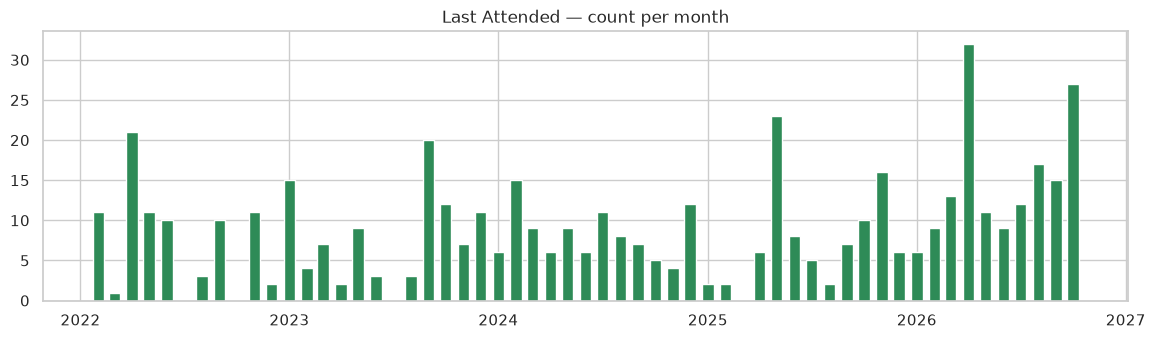

Last Attended,2022.0,2023.0,2024.0,2025.0,2026.0
rows per year,80,93,98,87,151


Most frequent 'last attended' dates (= last event for many people):


,members
date,
2026-10-08,27
2026-04-02,22
2022-04-07,19
2026-08-06,16
2025-05-08,16
2025-11-22,14
2026-03-05,13
2024-12-05,12


Of those who attended: last attendance within 6 months: 91 members


In [10]:
la = members["Last Attended"]
print(f"Members who never attended an event (null): {la.isna().sum()} ({la.isna().mean():.1%})")
display(profile_date(la).to_frame().T)
print("Most frequent 'last attended' dates (= last event for many people):")
display(la.value_counts().head(8).rename_axis("date").to_frame("members"))
members["days_since_attended"] = (ref_date - la).dt.days
print(f"Of those who attended: last attendance within 6 months: {(members['days_since_attended'] <= 182).sum()} members")

#### Engagement counters: `All time RSVPs`, `'Yes' RSVPs`, `'No' RSVPs`, `Events attended`, `No shows`

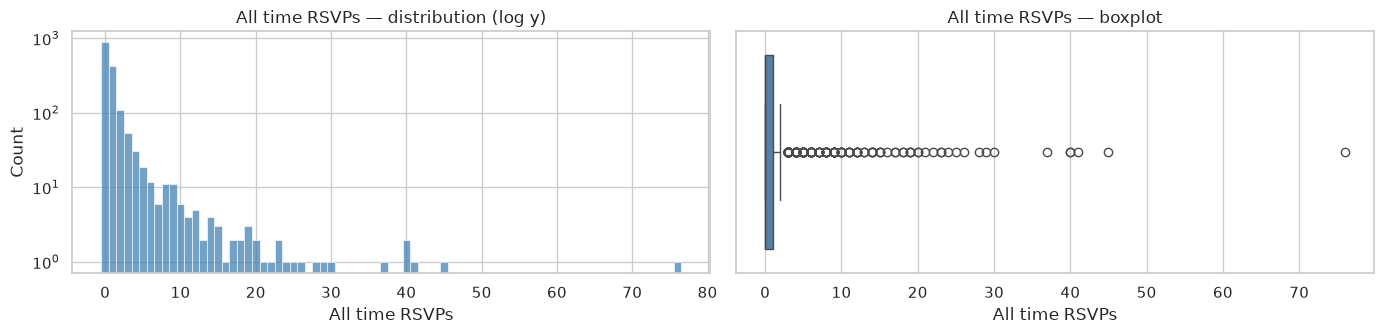

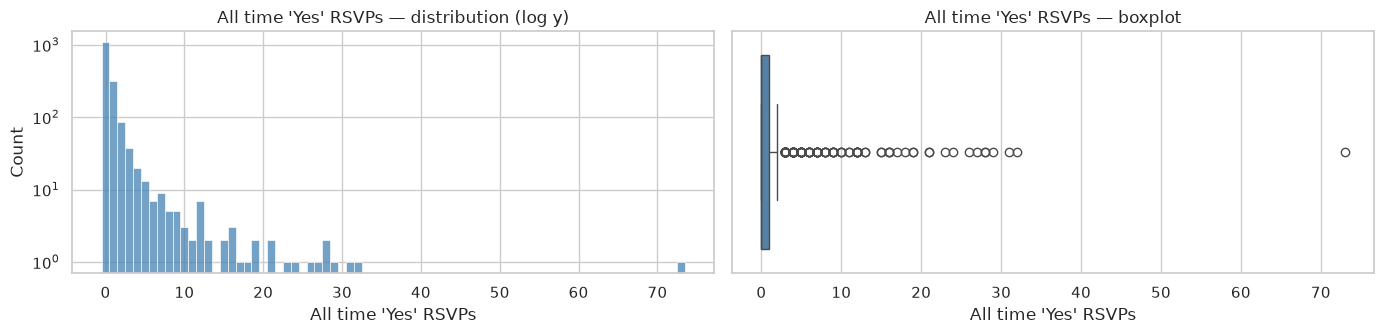

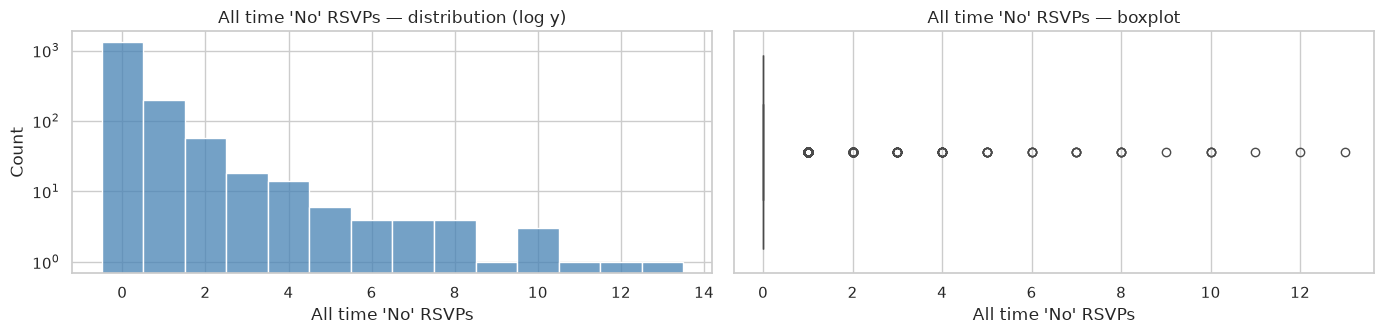

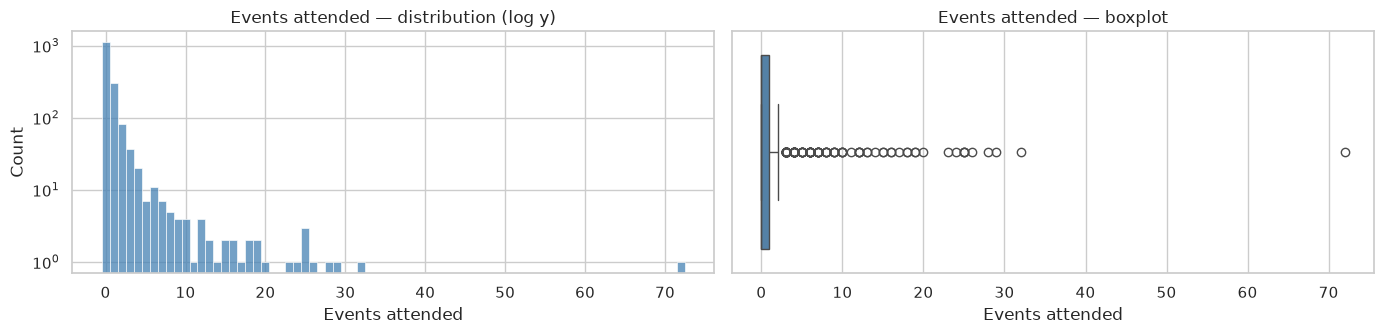

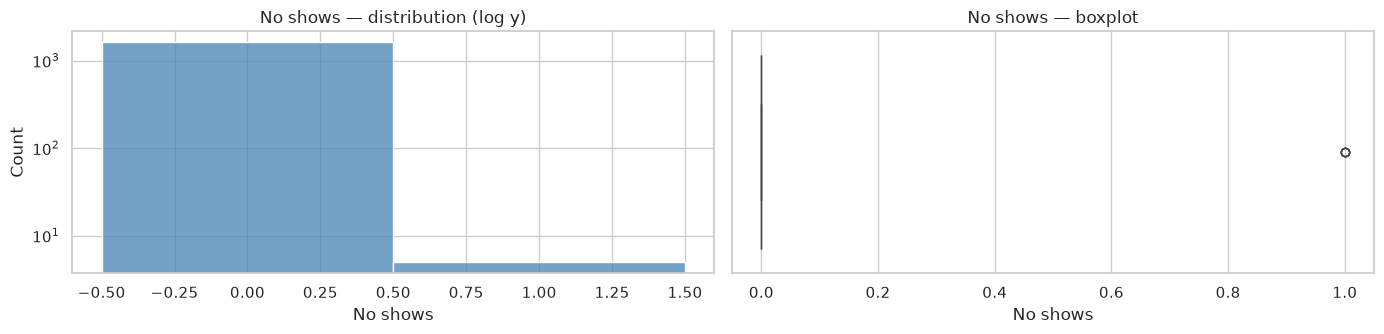

,All time RSVPs,All time 'Yes' RSVPs,All time 'No' RSVPs,Events attended,No shows
count,1620.00,1620.00,1620.00,1620.00,1.62e+03
sum,2332.00,1614.00,613.00,1507.00,5.00e+00
mean,1.44,1.00,0.38,0.93,3.09e-03
median,0.00,0.00,0.00,0.00,0.00e+00
std,4.21,3.43,1.15,3.30,5.55e-02
min,0.00,0.00,0.00,0.00,0.00e+00
q25,0.00,0.00,0.00,0.00,0.00e+00
q75,1.00,1.00,0.00,1.00,0.00e+00
q90,3.00,2.00,1.00,2.00,0.00e+00
q99,20.00,16.00,6.00,16.00,0.00e+00


In [11]:
count_stats = pd.concat([profile_numeric(members[c], log=True) for c in COUNT_COLS], axis=1)
count_stats

In [12]:
conc = pd.DataFrame({
    "members_with_>0": [(members[c] > 0).sum() for c in COUNT_COLS],
    "share_with_>0_%": [(members[c] > 0).mean() * 100 for c in COUNT_COLS],
    "top10%_share_of_total_%": [top_share(members[c]) * 100 for c in COUNT_COLS],
    "top1%_share_of_total_%": [top_share(members[c], 0.01) * 100 for c in COUNT_COLS],
}, index=COUNT_COLS).round(1)
display(conc)
check = members["All time RSVPs"] - members[YES_COL] - members["All time 'No' RSVPs"]
print(f"All time RSVPs == Yes + No for {(check == 0).mean():.1%} of members (other: waitlist/changed RSVPs); "
      f"rows where total < yes+no: {(check < 0).sum()}")
print(f"Members with Events attended > 'Yes' RSVPs: {(members['Events attended'] > members[YES_COL]).sum()}")

,members_with_>0,share_with_>0_%,top10%_share_of_total_%,top1%_share_of_total_%
All time RSVPs,732,45.2,68.2,22.7
All time 'Yes' RSVPs,536,33.1,73.4,27.0
All time 'No' RSVPs,313,19.3,75.4,23.0
Events attended,509,31.4,74.1,27.9
No shows,5,0.3,100.0,100.0


All time RSVPs == Yes + No for 94.2% of members (other: waitlist/changed RSVPs); rows where total < yes+no: 0
Members with Events attended > 'Yes' RSVPs: 0


#### `Intro`, `Photo`, `Role`

In [13]:
for c in ["Intro", "Photo", "Role"]:
    display(profile_categorical(members[c], plot=False))

Intro: 2 distinct values, 0 null


,count,%
Intro,,
No,1619,99.9
Yes,1,0.1


Photo: 2 distinct values, 0 null


,count,%
Photo,,
Yes,1221,75.4
No,399,24.6


Role: 5 distinct values, 0 null


,count,%
Role,,
MEMBER,1610,99.4
"EVENT ORGANIZER, MEMBER",5,0.3
EVENT ORGANIZER,3,0.2
"CO-ORGANIZER, MEMBER",1,0.1
ORGANIZER,1,0.1


### 1.3 Relationships & derived features

,members,%,share_of_attendances_%
segment,,,
1 never RSVP'd,888,54.8,0.0
"2 RSVP'd, never attended",223,13.8,0.0
3 attended once,303,18.7,20.1
4 attended 2-4,140,8.6,23.7
5 regular (5+),66,4.1,56.2


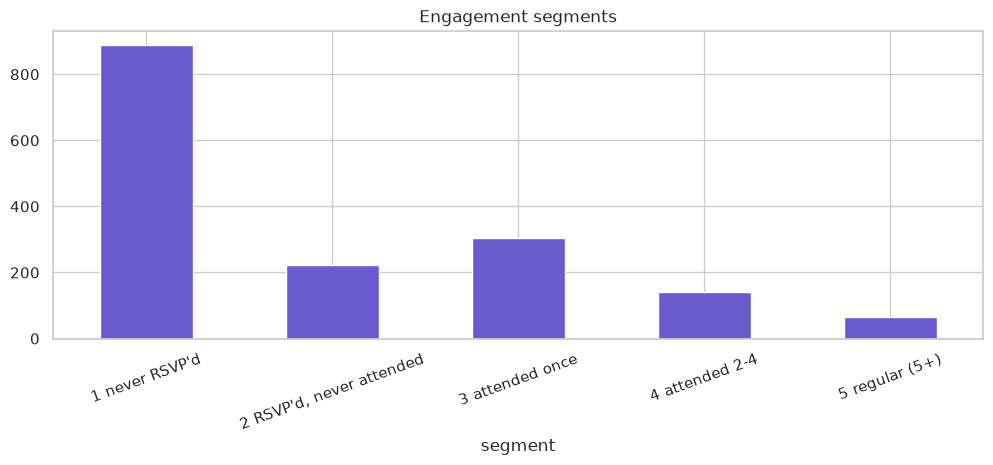

In [14]:
def segment(r):
    if r["All time RSVPs"] == 0:
        return "1 never RSVP'd"
    if r["Events attended"] == 0:
        return "2 RSVP'd, never attended"
    if r["Events attended"] == 1:
        return "3 attended once"
    if r["Events attended"] < 5:
        return "4 attended 2-4"
    return "5 regular (5+)"

members["segment"] = members.apply(segment, axis=1)
seg = members["segment"].value_counts().sort_index()
seg_tbl = pd.DataFrame({"members": seg, "%": (seg / seg.sum() * 100).round(1),
                        "share_of_attendances_%": (members.groupby("segment")["Events attended"].sum() / members["Events attended"].sum() * 100).round(1)})
display(seg_tbl)
ax = seg_tbl["members"].plot(kind="bar", color="slateblue", title="Engagement segments", rot=20)
plt.show()

In [15]:
yes = members[YES_COL]
conv = members.loc[yes > 0]
print(f"Attendance conversion (Events attended / Yes RSVPs), members with >=1 Yes: "
      f"overall {conv['Events attended'].sum() / conv[YES_COL].sum():.1%}, "
      f"median per member {(conv['Events attended'] / conv[YES_COL]).median():.0%}")

members["join_year"] = members["Joined Group on"].dt.year
cohort = members.groupby("join_year").agg(
    members=("Member ID", "size"),
    pct_ever_rsvp=("All time RSVPs", lambda s: (s > 0).mean() * 100),
    pct_ever_attended=("Events attended", lambda s: (s > 0).mean() * 100),
    mean_attended=("Events attended", "mean"),
    pct_regular=("Events attended", lambda s: (s >= 5).mean() * 100),
    pct_visited_90d=("days_since_visit", lambda s: (s <= 90).mean() * 100),
).round(1)
print("Engagement by join-cohort year:")
display(cohort)

Attendance conversion (Events attended / Yes RSVPs), members with >=1 Yes: overall 93.4%, median per member 100%
Engagement by join-cohort year:


,members,pct_ever_rsvp,pct_ever_attended,mean_attended,pct_regular,pct_visited_90d
join_year,,,,,,
2022,285,64.6,52.6,2.3,10.9,11.6
2023,247,59.9,42.5,1.3,5.7,8.1
2024,273,51.3,35.5,0.8,2.6,11.7
2025,439,37.4,21.9,0.5,2.7,13.9
2026,376,25.5,16.2,0.2,0.5,30.3


,mean attended,% ever attended
Photo,,
No,0.44,22.81
Yes,1.09,34.23


,mean attended,% ever attended
is_zurich,,
elsewhere,0.68,33.33
Zürich,1.03,30.68


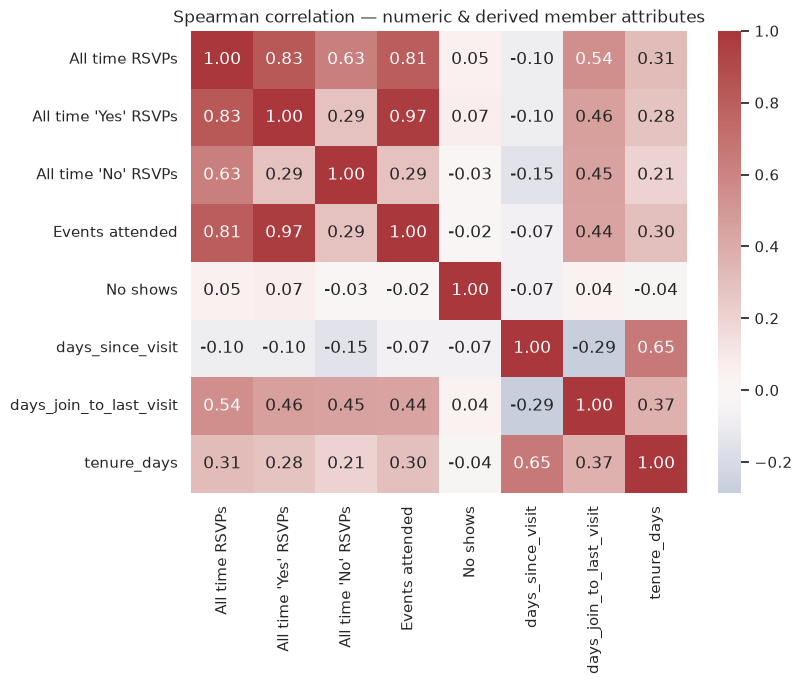

In [16]:
by_photo = members.groupby("Photo")[["Events attended"]].agg(["mean", lambda s: (s > 0).mean() * 100]).round(2)
by_photo.columns = ["mean attended", "% ever attended"]
by_loc = members.groupby("is_zurich")[["Events attended"]].agg(["mean", lambda s: (s > 0).mean() * 100]).round(2)
by_loc.columns = ["mean attended", "% ever attended"]
by_loc.index = by_loc.index.map({True: "Zürich", False: "elsewhere"})
display(by_photo, by_loc)

num = members[COUNT_COLS + ["days_since_visit", "days_join_to_last_visit"]].assign(
    tenure_days=(ref_date - members["Joined Group on"]).dt.days)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Spearman correlation — numeric & derived member attributes"); plt.show()

### 1.4 Key findings — members

**Data quality**
- 1,620 members, one row each, with a unique `Member ID`. `Title` is 100% empty and `Intro` is almost constant (1 "Yes"), so neither tells us anything. Names are not unique (148 duplicates), and the profile URL is just the ID, so all three columns were dropped.
- `Location` is free text. Normalising it ("Zurich, 25" → "Zürich") cuts 202 values to 197.
- **26 members have a last visit earlier than their join date** (2–48 days before). None of them ever attended, so these are most likely members who left and rejoined.

**Who the members are**
- **72% are located in Zürich.** The rest is a long tail of Swiss towns (Winterthur, Zug, Luzern, Basel) and international cities (London, Berlin, Paris, Amsterdam…).
- Join dates run from **2022-01-16 to 2026-10-25**. Joins are increasing: 285 (2022), 247, 273, **439 (2025)**, and 376 in 2026 up to late October. The biggest single day is **2026-10-19 with 18 joins**.
- 10 members (0.6%) hold an organizer role. 75% have a profile photo.

**Engagement is very concentrated, and most members never engage**
- **54.8% never RSVP'd and 68.6% never attended an event.** Only 509 members (31%) ever attended.
- **66 "regulars" (5+ events, 4.1% of members) account for 56% of all attendances.** The top 1% of members account for 28%. All counters are extremely right-skewed (skew 8–10). The maximum is 72 events attended by one member.
- **41% of members never came back to the group page after the day they joined.** 75% have not visited in more than 6 months.
- **RSVPs are reliable once given:** about 93% of 'Yes' RSVPs turn into attendance, and there are only **5 recorded no-shows** in the whole group's history.
- **Newer cohorts engage less:** 52.6% of 2022 joiners have attended at least once, against 21.9% of 2025 joiners and 16.2% of 2026 joiners. The share who became regulars falls from 10.9% to 2.7%. Part of this is simply that newer members have had less time, but 2025 joiners have had a full year and still lag well behind.
- Members with a profile photo are more likely to attend (34% ever attended vs 23% without). Members outside Zürich attend about as often as those in Zürich (33% vs 31%).

---
## 2. `group_attendance.csv`

One row per RSVP of a member to an event: event identity and date, RSVP answer, recorded attendance status and number of guests.

### 2.1 Summary statistics

In [17]:
att_raw = pd.read_csv(DATA_DIR / "group_attendance.csv")
overview(att_raw)

Shape: 998 rows x 9 columns | fully duplicated rows: 0


,dtype,non_null,null,null_%,n_unique,example
Member ID,int64,998,0,0.0,383,295518783
Member Name,str,998,0,0.0,366,<redacted>
Event ID,int64,998,0,0.0,36,304176992
Event Title,str,998,0,0.0,32,Philosophy of 'The Matrix' Movie
Event Local Date and Time,str,998,0,0.0,36,"November 7, 2024 12:50"
RSVP Status,str,998,0,0.0,3,YES
Attendance Status,str,998,0,0.0,3,UNKNOWN
Status,str,998,0,0.0,3,not_confirmed
Guests,int64,998,0,0.0,3,0


In [18]:
att = att_raw.copy()
print(f"Member Name: {att['Member Name'].nunique()} distinct names for {att['Member ID'].nunique()} member IDs "
      f"(names are not unique identifiers)")
att = att.drop(columns=["Member Name"])
att["event_dt"] = pd.to_datetime(att["Event Local Date and Time"], format="%B %d, %Y %H:%M")
att["event_date"] = att["event_dt"].dt.normalize()
print(f"Duplicate (Member ID, Event ID) pairs: {att.duplicated(['Member ID', 'Event ID']).sum()}")
display(att.describe(include="all").T)

Member Name: 366 distinct names for 383 member IDs (names are not unique identifiers)
Duplicate (Member ID, Event ID) pairs: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Member ID,998.0,NaN,NaN,NaN,308493775.9,409858.0,219948811.5,312609232.0,396168330.0,484148024.0,121014526.42
Event ID,998.0,NaN,NaN,NaN,311552803.03,304176992.0,308541338.0,311633744.0,314199178.0,316524673.0,3525903.23
Event Title,998,32,Stoic Training Session,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Event Local Date and Time,998,36,"May 8, 2025 12:50",60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RSVP Status,998,3,YES,735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attendance Status,998,3,UNKNOWN,946,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,998,3,not_confirmed,720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Guests,998.0,NaN,NaN,NaN,0.02,0.0,0.0,0.0,0.0,2.0,0.14
event_dt,998,NaN,NaN,NaN,2025-12-05 21:41:59.639278,2024-11-07 12:50:00,2025-06-27 01:00:00,2025-12-04 12:50:00,2026-05-07 12:50:00,2026-10-08 12:50:00,NaN
event_date,998,NaN,NaN,NaN,2025-12-05 11:31:08.537074,2024-11-07 00:00:00,2025-06-27 00:00:00,2025-12-04 00:00:00,2026-05-07 00:00:00,2026-10-08 00:00:00,NaN


In [19]:
events = (att.groupby(["Event ID", "event_date", "Event Title"])
          .agg(rsvp_rows=("Member ID", "size"),
               yes=("RSVP Status", lambda s: (s == "YES").sum()),
               no=("RSVP Status", lambda s: (s == "NO").sum()),
               waitlist=("RSVP Status", lambda s: (s == "WAITLIST").sum()),
               excused=("Attendance Status", lambda s: (s == "EXCUSED_ABSENCE").sum()),
               no_show=("Attendance Status", lambda s: (s == "NO_SHOW").sum()),
               guests=("Guests", "sum"))
          .reset_index().sort_values("event_date").reset_index(drop=True))
events["expected_attendees"] = events["yes"] - events["excused"] - events["no_show"] + events["guests"]
events["no_rate_%"] = (events["no"] / events["rsvp_rows"] * 100).round(1)
print(f"{len(events)} events, {events['event_date'].min().date()} -> {events['event_date'].max().date()}")
events[["yes", "no", "waitlist", "excused", "no_show", "guests", "expected_attendees", "rsvp_rows"]].describe().T

36 events, 2024-11-07 -> 2026-10-08


,count,mean,std,min,25%,50%,75%,max
yes,36.0,20.42,10.62,3.0,11.00,19.0,29.00,47.0
no,36.0,6.28,3.43,0.0,3.75,6.0,8.25,14.0
waitlist,36.0,1.03,2.35,0.0,0.00,0.0,0.00,8.0
excused,36.0,1.31,1.37,0.0,0.00,1.0,2.00,4.0
no_show,36.0,0.14,0.83,0.0,0.00,0.0,0.00,5.0
guests,36.0,0.47,1.30,0.0,0.00,0.0,0.00,7.0
expected_attendees,36.0,19.44,10.58,3.0,10.75,18.5,27.00,43.0
rsvp_rows,36.0,27.72,12.61,3.0,20.75,25.5,34.00,60.0


### 2.2 EDA per attribute

#### `Member ID`

383 distinct members RSVP'd in this period (23.6% of the member base); all in members file: True


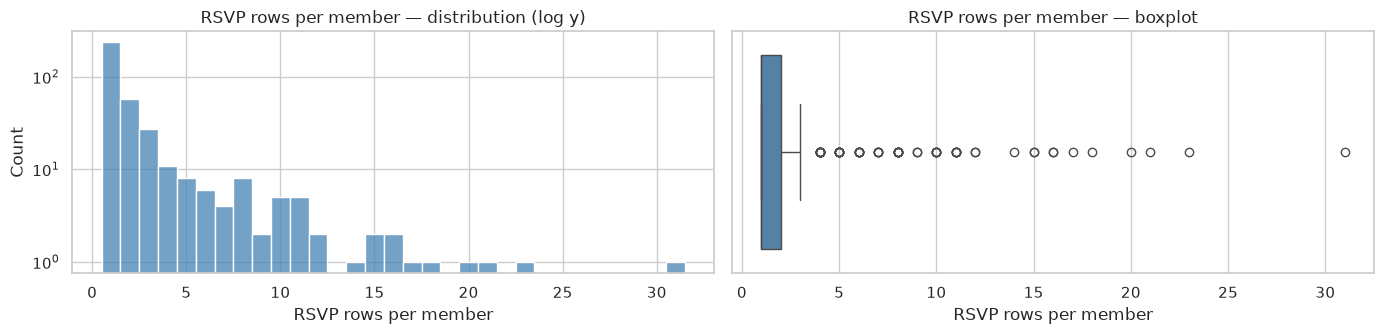

,count,sum,mean,median,std,min,q25,q75,q90,q99,max,skew,kurtosis,zero_%,iqr_outliers
RSVP rows per member,383.0,998.0,2.61,1.0,3.64,1.0,1.0,2.0,6.0,18.36,31.0,3.69,17.02,0.0,62.0


Only 1 RSVP: 61.6% | 5+ RSVPs: 13.3% | top 10% of members hold 45% of RSVPs


In [20]:
per_member = att.groupby("Member ID").agg(rsvps=("Event ID", "size"),
                                          yes=("RSVP Status", lambda s: (s == "YES").sum()))
print(f"{len(per_member)} distinct members RSVP'd in this period "
      f"({len(per_member) / members['Member ID'].nunique():.1%} of the member base); all in members file: "
      f"{per_member.index.isin(members['Member ID']).all()}")
display(profile_numeric(per_member["rsvps"].rename("RSVP rows per member"), log=True).to_frame().T)
print(f"Only 1 RSVP: {(per_member['rsvps'] == 1).mean():.1%} | 5+ RSVPs: {(per_member['rsvps'] >= 5).mean():.1%} | "
      f"top 10% of members hold {top_share(per_member['rsvps']):.0%} of RSVPs")

#### `Event ID` & `Event Title`

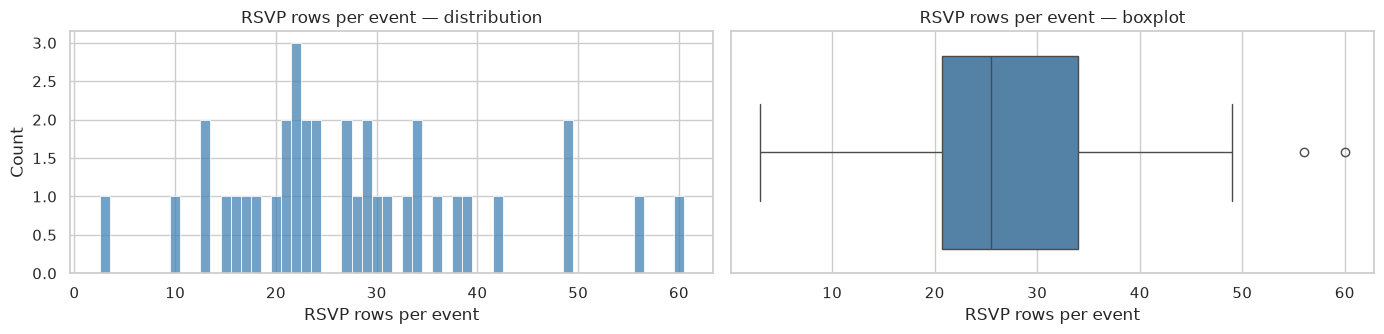

,count,sum,mean,median,std,min,q25,q75,q90,q99,max,skew,kurtosis,zero_%,iqr_outliers
RSVP rows per event,36.0,998.0,27.72,25.5,12.61,3.0,20.75,34.0,45.5,58.6,60.0,0.71,0.56,0.0,2.0


36 events share 32 titles; repeated titles:


,events
Event Title,
Stoic Training Session,5


Largest and smallest events by YES RSVPs:


,event_date,Event Title,yes,no,waitlist,expected_attendees
24,2026-04-02,Who Do You Think You Are? – From Nietzsche to ...,47,9,0,43
21,2026-02-05,"Aristotle on Ethics - Eudaimonia, Virtue and T...",42,6,1,40
6,2025-05-08,Modern Existential Crisis meets Existentialism,38,14,8,39
23,2026-03-05,Stoicism and Awareness: Lessons from Seneca an...,38,11,0,34
18,2025-11-22,LONG NIGHT OF PHILOSOPHY: Between Words and Si...,34,5,0,39
32,2026-08-11,Stoic Workshop - Examining Our Habits (Laptop ...,3,0,0,3
34,2026-09-08,Stoic Workshop - Remodeling Our Habits (Laptop...,8,2,0,8
12,2025-07-09,Stoic Training Session,9,4,0,9


In [21]:
display(profile_numeric(events["rsvp_rows"].rename("RSVP rows per event"), bins=15).to_frame().T)
titles = att.drop_duplicates("Event ID")["Event Title"].value_counts()
print(f"{att['Event ID'].nunique()} events share {att['Event Title'].nunique()} titles; repeated titles:")
display(titles[titles > 1].to_frame("events"))
print("Largest and smallest events by YES RSVPs:")
display(pd.concat([events.nlargest(5, "yes"), events.nsmallest(3, "yes")])
        [["event_date", "Event Title", "yes", "no", "waitlist", "expected_attendees"]])

,events,mean_yes,median_yes,mean_waitlist,main_weekday
format,,,,,
Monthly talk,25,23.8,20.0,0.4,Thursday
Social / special,3,22.7,20.0,2.0,Friday
Stoic training / workshop,8,9.0,9.5,2.8,Tuesday


Monthly talks: named classic thinker/tradition in the title vs other topics


,size,mean,median
classic_canon,,,
other,13,19.9,19.0
classic canon,12,28.0,26.0


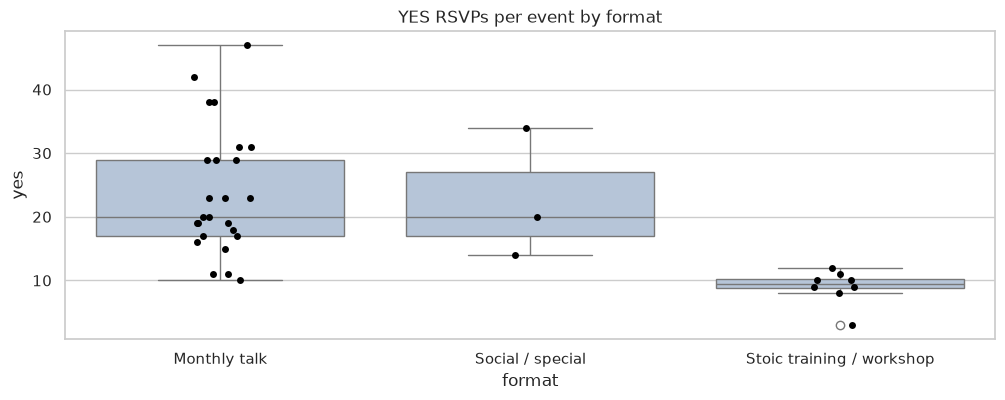

In [22]:
def event_format(title: str) -> str:
    t = title.lower()
    if re.search(r"stoic (training|workshop)", t):
        return "Stoic training / workshop"
    if re.search(r"walk|picnic|social|long night", t):
        return "Social / special"
    return "Monthly talk"

CANON = r"aristotle|plato|kant|socrates|nietzsche|seneca|locke|diogenes|dostoyevsky|dōgen|tao te ching|existentialism"
events["format"] = events["Event Title"].map(event_format)
events["classic_canon"] = events["Event Title"].str.contains(CANON, case=False, regex=True)
events["weekday"] = events["event_date"].dt.day_name()

fmt = events.groupby("format").agg(events=("Event ID", "size"), mean_yes=("yes", "mean"), median_yes=("yes", "median"),
                                   mean_waitlist=("waitlist", "mean"), main_weekday=("weekday", lambda s: s.mode()[0]))
display(fmt.round(1))
talks = events[events["format"] == "Monthly talk"]
print("Monthly talks: named classic thinker/tradition in the title vs other topics")
display(talks.groupby("classic_canon")["yes"].agg(["size", "mean", "median"]).rename(index={True: "classic canon", False: "other"}).round(1))
ax = sns.boxplot(data=events, x="format", y="yes", color="lightsteelblue")
sns.stripplot(data=events, x="format", y="yes", color="black", ax=ax)
ax.set_title("YES RSVPs per event by format"); plt.show()

#### `Event Local Date and Time`

Events per weekday:
event_dt
Monday        0
Tuesday       4
Wednesday     2
Thursday     26
Friday        3
Saturday      1
Sunday        0

Clock time as exported (12-hour format without AM/PM, so morning or afternoon is ambiguous):
Event Local Date and Time
12:50    25
1:00     10
2:00      1


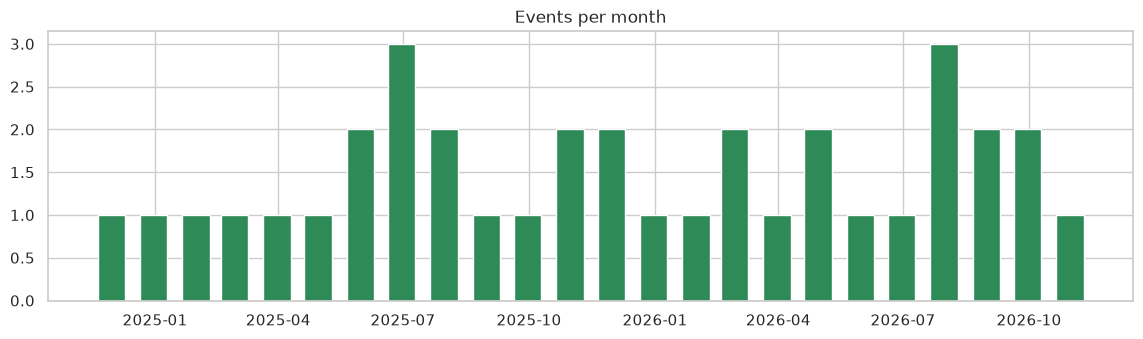

Months without any event: 0 of 24 
Events held on the first Thursday of a month: 20 of 36 events
Events per year:
event_date
2024     2
2025    18
2026    16


In [23]:
ev_dt = events.merge(att.drop_duplicates("Event ID")[["Event ID", "event_dt", "Event Local Date and Time"]], on="Event ID")
print("Events per weekday:"); print(ev_dt["event_dt"].dt.day_name().value_counts().reindex(WEEKDAYS, fill_value=0).to_string())
print("\nClock time as exported (12-hour format without AM/PM, so morning or afternoon is ambiguous):")
print(ev_dt["Event Local Date and Time"].str.split().str[-1].value_counts().to_string())
per_month = events.set_index("event_date").resample("ME").agg({"Event ID": "count", "yes": "sum"})
per_month.columns = ["events", "yes_rsvps"]
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(per_month.index, per_month["events"], width=20, color="seagreen")
ax.set_title("Events per month"); plt.show()
empty = per_month.index[per_month["events"] == 0].strftime("%Y-%m").tolist()
print(f"Months without any event: {len(empty)} of {len(per_month)} {empty if empty else ''}")
print(f"Events held on the first Thursday of a month: "
      f"{((ev_dt['event_dt'].dt.day_name() == 'Thursday') & (ev_dt['event_dt'].dt.day <= 7)).sum()} of {len(ev_dt)} events")
print("Events per year:"); print(events["event_date"].dt.year.value_counts().sort_index().to_string())

#### `RSVP Status`, `Attendance Status`, `Status`

In [24]:
for c in ["RSVP Status", "Attendance Status", "Status"]:
    display(profile_categorical(att[c], plot=False))
print("RSVP Status x Attendance Status:")
display(pd.crosstab(att["RSVP Status"], att["Attendance Status"], margins=True))
print("Attendance Status x Status:")
display(pd.crosstab(att["Status"], [att["RSVP Status"], att["Attendance Status"]]))

RSVP Status: 3 distinct values, 0 null


,count,%
RSVP Status,,
YES,735,73.6
NO,226,22.6
WAITLIST,37,3.7


Attendance Status: 3 distinct values, 0 null


,count,%
Attendance Status,,
UNKNOWN,946,94.8
EXCUSED_ABSENCE,47,4.7
NO_SHOW,5,0.5


Status: 3 distinct values, 0 null


,count,%
Status,,
not_confirmed,720,72.1
not_coming,273,27.4
no_show,5,0.5


RSVP Status x Attendance Status:


Attendance Status,EXCUSED_ABSENCE,NO_SHOW,UNKNOWN,All
RSVP Status,,,,
NO,0,0,226,226
WAITLIST,0,0,37,37
YES,47,5,683,735
All,47,5,946,998


Attendance Status x Status:


RSVP Status            NO WAITLIST             YES                
Attendance Status UNKNOWN  UNKNOWN EXCUSED_ABSENCE NO_SHOW UNKNOWN
Status                                                            
no_show                 0        0               0       5       0
not_coming            226        0              47       0       0
not_confirmed           0       37               0       0     683

In [25]:
# Is `Status` fully determined by the other two columns?
derived = np.select(
    [att["Attendance Status"].eq("NO_SHOW"),
     att["RSVP Status"].eq("NO") | att["Attendance Status"].eq("EXCUSED_ABSENCE")],
    ["no_show", "not_coming"], default="not_confirmed")
print(f"`Status` reproducible from RSVP + Attendance status: {(derived == att['Status']).mean():.1%} of rows")
print(f"Share of YES RSVPs with a recorded attendance outcome (not UNKNOWN): "
      f"{(att.loc[att['RSVP Status'] == 'YES', 'Attendance Status'] != 'UNKNOWN').mean():.1%}")

`Status` reproducible from RSVP + Attendance status: 100.0% of rows
Share of YES RSVPs with a recorded attendance outcome (not UNKNOWN): 7.1%


#### `Guests`

In [26]:
display(profile_categorical(att["Guests"], plot=False))
print(f"Total guests brought: {att['Guests'].sum()} across {(att['Guests'] > 0).sum()} RSVPs")

Guests: 3 distinct values, 0 null


,count,%
Guests,,
0,982,98.4
1,15,1.5
2,1,0.1


Total guests brought: 17 across 16 RSVPs


### 2.3 Trends, retention & cross-check with members

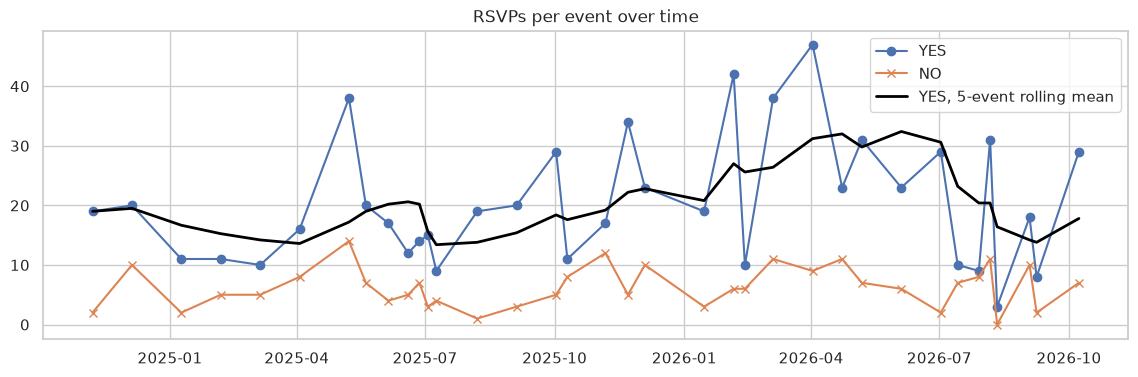

Average per event, by year:


,yes,no,waitlist,expected_attendees,events
event_date,,,,,
2024,19.5,6.0,0.0,20.5,2
2025,18.1,6.0,0.9,17.8,18
2026,23.1,6.6,1.2,21.2,16


Events with a waitlist: 7


,event_date,Event Title,yes,waitlist
6,2025-05-08,Modern Existential Crisis meets Existentialism,38,8
10,2025-06-27,Philosophical Minds Social - Picnic and Swim,14,6
16,2025-10-10,Stoic Training Session,11,3
21,2026-02-05,"Aristotle on Ethics - Eudaimonia, Virtue and T...",42,1
22,2026-02-13,Stoic Training Session,10,6
29,2026-07-14,Stoic Training Session,10,6
30,2026-07-29,Stoic Training Session (Laptop needed),9,7


In [27]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(events["event_date"], events["yes"], marker="o", label="YES")
ax.plot(events["event_date"], events["no"], marker="x", label="NO")
ax.plot(events["event_date"], events["yes"].rolling(5, min_periods=1).mean(), color="black", lw=2, label="YES, 5-event rolling mean")
ax.set_title("RSVPs per event over time"); ax.legend(); plt.show()

by_year = events.groupby(events["event_date"].dt.year)[["yes", "no", "waitlist", "expected_attendees"]].mean().round(1)
by_year["events"] = events.groupby(events["event_date"].dt.year).size()
print("Average per event, by year:"); display(by_year)
print(f"Events with a waitlist: {(events['waitlist'] > 0).sum()}")
display(events.loc[events["waitlist"] > 0, ["event_date", "Event Title", "yes", "waitlist"]])

Members with >=1 YES in this file: 273; came back for a 2nd event: 37.4%; 5+ events: 15.8%


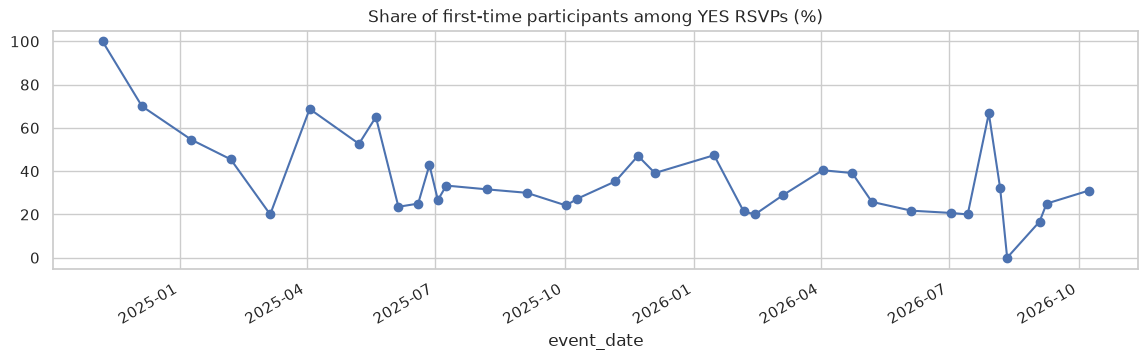

Mean first-timer share per event (excluding the first event of the file): 35%


In [28]:
yes_rows = att[att["RSVP Status"] == "YES"].sort_values("event_dt")
first = yes_rows.groupby("Member ID")["event_dt"].min().rename("first_event")
n_yes = yes_rows.groupby("Member ID").size().rename("n_yes")
ret = pd.concat([first, n_yes], axis=1)
print(f"Members with >=1 YES in this file: {len(ret)}; came back for a 2nd event: {(ret['n_yes'] >= 2).mean():.1%}; "
      f"5+ events: {(ret['n_yes'] >= 5).mean():.1%}")

# Share of each event's YES list that are first-timers vs returning
yes_rows = yes_rows.merge(first, on="Member ID")
yes_rows["first_timer"] = yes_rows["event_dt"] == yes_rows["first_event"]
ft = yes_rows.groupby("Event ID")["first_timer"].mean().rename("first_timer_share")
events = events.merge(ft, on="Event ID", how="left")
ax = (events.set_index("event_date")["first_timer_share"] * 100).plot(marker="o", figsize=(14, 3.5),
                                                                      title="Share of first-time participants among YES RSVPs (%)")
plt.show()
print(f"Mean first-timer share per event (excluding the first event of the file): {events['first_timer_share'].iloc[1:].mean():.0%}")

In [29]:
xm = per_member.join(members.set_index("Member ID")[["All time 'Yes' RSVPs", "Events attended", "segment"]])
print(f"Members whose YES count in this file > all-time 'Yes' RSVPs in members file: "
      f"{(xm['yes'] > xm[YES_COL]).sum()} of {len(xm)}")
print(f"Spearman corr(YES in this file, all-time Yes RSVPs): {xm['yes'].corr(xm[YES_COL], method='spearman'):.2f}")
print(f"Attendance-file YES rows: {(att['RSVP Status'] == 'YES').sum()} vs all-time Yes RSVPs in members file: "
      f"{members[YES_COL].sum()}, so this file covers part of the group's history only")
print("Segment (from members file) of members appearing in the attendance file:")
display(xm["segment"].value_counts().sort_index().to_frame("members"))

Members whose YES count in this file > all-time 'Yes' RSVPs in members file: 0 of 383
Spearman corr(YES in this file, all-time Yes RSVPs): 0.91
Attendance-file YES rows: 735 vs all-time Yes RSVPs in members file: 1614, so this file covers part of the group's history only
Segment (from members file) of members appearing in the attendance file:


,members
segment,
"2 RSVP'd, never attended",117
3 attended once,142
4 attended 2-4,75
5 regular (5+),49


### 2.4 Key findings — attendance

**Data quality**
- 998 RSVP rows for **36 events** and **383 members**, from **2024-11-07 to 2026-10-08**. There are no duplicate member-event pairs, and every member ID is present in the members file.
- **`Status` is fully redundant.** It can be rebuilt exactly (100%) from `RSVP Status` + `Attendance Status`.
- **Attendance is rarely recorded:** 94.8% of rows are `UNKNOWN`, and only 7.1% of YES RSVPs have an outcome (excused or no-show). So this file measures *intent* (RSVPs), not actual turnout.
- The event time is exported in 12-hour format **without AM/PM** (12:50, 1:00, 2:00), so the time of day is ambiguous. The analysis uses dates only.
- This file covers 735 of the 1,614 all-time 'Yes' RSVPs, so it is a partial window. It is consistent with the members file: no member has more YESes here than their lifetime count, and Spearman ρ = 0.91.

**Events**
- The schedule has three formats:
  - **25 monthly talks**, almost always on a Thursday (20 of the 36 events fall on the first Thursday of a month), averaging **23.8 YES RSVPs**.
  - **8 Stoic training sessions/workshops** (Tue/Wed/Fri), averaging **9 YES RSVPs**. Despite being small, they have **5 of the 7 waitlists**, which suggests limited capacity rather than low demand. The exceptions are the two "Laptop needed" workshops in Aug/Sep 2026, which drew only 3 and 8 YES and had no waitlist.
  - **3 social or special events** (Uetliberg walk, picnic, Long Night of Philosophy).
- **Every month in the period had at least one event.** Events are getting bigger: on average 23.1 YES per event in 2026 against 18.1 in 2025.
- **Talks on classic philosophers draw more people:** talks that name a classic thinker or tradition (Aristotle, Kant, Plato, Nietzsche, Seneca…) average **28 YES**, against **20** for other topics. The top events were *Nietzsche to Taylor on identity* (47), *Aristotle on Ethics* (42), *Existentialism* (38) and *Stoicism & Seneca* (38).
- RSVP mix: 73.6% YES, 22.6% NO and 3.7% waitlist. Guests are negligible (17 in total).

**Members**
- Few people come back: **61.6% of the members in this file RSVP'd only once**. Of the 273 members with at least one YES, **37.4% came back for a second event** and 15.8% came to 5 or more. The top 10% of members hold 45% of the RSVPs.
- About **35% of each event's YES list are first-timers**, so the group depends on a steady flow of new people to keep its events full.

---
## 3. Overall key findings

1. **The group is growing, but most members never take part.** Joins hit a record in 2025 and events are getting bigger (23 YES/event in 2026). Yet **69% of members have never attended** and 41% never returned after the day they joined.
2. **A small core keeps the group going.** 66 regulars (4% of members) account for **56% of all attendances**, and the top 10% of members in the attendance file hold 45% of RSVPs.
3. **The main problem is getting people to a second event.** Only 37% of people who RSVP YES come back for another event, and each event is about one-third first-timers. Newer cohorts convert to attendees and regulars much less than the 2022–2023 cohorts.
4. **People who say yes show up.** About 93% of 'Yes' RSVPs become attendances, and there are only 5 recorded no-shows. The NO-rate is about 23%.
5. **What draws people:** Thursday monthly talks on **classic philosophers** (about 28 YES on average, against about 20 for other topics). Stoic small-group sessions regularly hit waitlists, which suggests room for more sessions or a larger room. The "laptop needed" workshops are the exception.
6. **Data caveats:**
   - Attendance outcomes are almost never recorded (95% `UNKNOWN`).
   - The event times have no AM/PM.
   - `Title`, `Intro` and `Status` carry no extra information.
   - Location is free text.
   - 26 members have a last visit before their join date, most likely because they rejoined.